<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/10_KMeans_Clustering_Airline_Markets_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10. K-Means Clustering: Kinds of Airline Markets

So far every model had an answer to learn (late or not, which airline leads). **Clustering** has no answer column.
It looks for groups of similar markets on its own. This is **unsupervised learning**.

A network planner might ask: *what kinds of markets do we fly?* K-means splits the 200 busiest U.S. markets into $K$
groups using distance, fare and low-cost competition, and we then read what each group means.

- **No y:** clustering has no answer column to predict
- **Inputs (X):** `distance_mi`, `avg_fare`, `lcc_share`

Slides: W3.1, clustering, K-means algorithm, choosing K (elbow method).

> **Data.** The 200 busiest U.S. domestic markets in 2019 (both directions combined), read straight from the course
> GitHub repository. Source: Sabre Market Intelligence, licensed to Embry-Riddle.

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

## 1. Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

routes = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/sabre_routes_2019.csv')
routes['market'] = routes['airport_1'] + '-' + routes['airport_2']
routes.head()

,airport_1,airport_2,distance_mi,passengers,avg_fare,lcc_share,hhi,top_airline,market
0,JFK,LAX,2470.0,3115042.0,349.29,0.321,0.269,DL,JFK-LAX
1,LGA,ORD,731.0,2600397.0,174.47,0.086,0.293,AA,LGA-ORD
2,LAX,SFO,337.0,2289910.0,104.55,0.203,0.212,AS,LAX-SFO
3,LAX,ORD,1741.0,1853120.0,187.84,0.146,0.332,UA,LAX-ORD
4,LAS,LAX,236.0,1831441.0,73.20,0.438,0.180,WN,LAS-LAX


| Column | Meaning |
|---|---|
| `airport_1`, `airport_2` | the two airports of the market |
| `distance_mi` | distance in miles |
| `passengers` | passengers in 2019 |
| `avg_fare` | average base fare ($) |
| `lcc_share` | share of passengers on low-cost airlines (0 to 1) |
| `hhi` | market concentration, the Herfindahl-Hirschman Index: square each airline's share and add them up (1 = one airline carries everyone) |
| `top_airline` | the airline with the most passengers: AA American, DL Delta, UA United, WN Southwest, AS Alaska, B6 JetBlue, HA Hawaiian, NK Spirit |

## 2. Standardize

K-means groups markets by distance between points, so, as with KNN in notebook 9, each input must be on the same
scale. Otherwise miles would decide everything.

In [2]:
features = ['distance_mi', 'avg_fare', 'lcc_share']
scaler = StandardScaler()
scaled = scaler.fit_transform(routes[features])     # fit and transform in one step
scaled[:3].round(2)

array([[ 2.13,  2.85, -0.2 ],
       [-0.56,  0.08, -1.03],
       [-1.17, -1.03, -0.62]])

## 3. How Many Groups? The Elbow Method

K-means works like this: pick $K$ centers at random, assign each market to its nearest center, move each center to
the average of its markets, and repeat until nothing changes. `n_init=10` runs the whole thing 10 times from
different starts and keeps the best.

**Inertia** is the sum of squared distances from each market to its center: how tight the groups are. It always
falls as $K$ grows, so look for the **elbow**, where adding a group stops helping much.

In [3]:
rows = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=320)
    km.fit(scaled)
    rows.append({'k': k, 'inertia': km.inertia_})

elbow = pd.DataFrame(rows).round(1)
elbow

,k,inertia
0,1,600.0
1,2,323.6
2,3,205.5
3,4,170.4
4,5,142.6
5,6,125.2
6,7,110.0
7,8,95.8


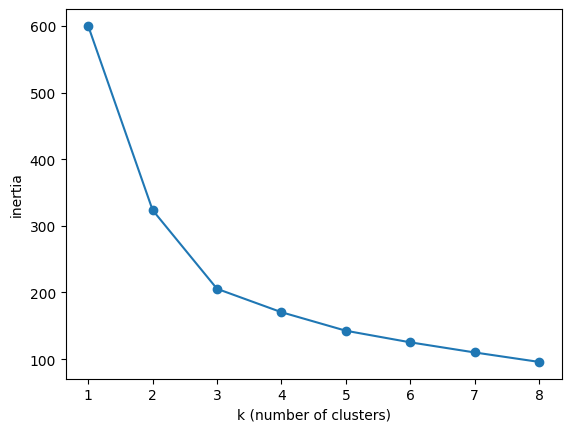

In [4]:
# Figure 1
plt.plot(elbow['k'], elbow['inertia'], marker='o')
plt.xlabel('k (number of clusters)')
plt.ylabel('inertia')
plt.show()

Going from 1 to 2 groups and from 2 to 3 cuts inertia sharply; after 3 the gains are small. We take $K = 3$.

## 4. Three Groups

In [5]:
km = KMeans(n_clusters=3, n_init=10, random_state=320)
routes['cluster'] = km.fit_predict(scaled)
routes['cluster'].value_counts().sort_index()

cluster
0    43
1    99
2    58
Name: count, dtype: int64

The **centroid** of each group is its average market. Turn the centers back into miles, dollars and shares:

In [6]:
centers = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=features).round(2)
centers

,distance_mi,avg_fare,lcc_share
0,2102.19,261.75,0.20
1,890.68,157.82,0.25
2,689.26,120.93,0.73


In [7]:
# the five busiest markets in each group
for c in range(3):
    print(c, routes[routes['cluster'] == c].sort_values('passengers', ascending=False)['market'].head().tolist())

0 ['JFK-LAX', 'LAX-ORD', 'JFK-SFO', 'EWR-SFO', 'EWR-LAX']
1 ['LGA-ORD', 'LAX-SFO', 'LAX-SEA', 'ATL-LGA', 'HNL-OGG']
2 ['LAS-LAX', 'EWR-MCO', 'MCO-PHL', 'DEN-PHX', 'FLL-LGA']


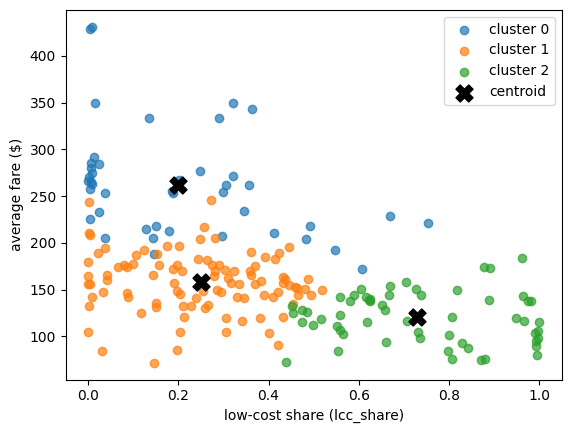

In [8]:
# Figure 2
for c in range(3):
    part = routes[routes['cluster'] == c]
    plt.scatter(part['lcc_share'], part['avg_fare'], label='cluster %d' % c, alpha=0.7)
plt.scatter(centers['lcc_share'], centers['avg_fare'], color='black', marker='X', s=150, label='centroid')
plt.xlabel('low-cost share (lcc_share)')
plt.ylabel('average fare ($)')
plt.legend()
plt.show()

**Read the groups.**

- **Cluster 0, long-haul:** about 2,100 miles and $262, little low-cost competition. Coast-to-coast markets such as
  JFK-LAX and EWR-SFO.
- **Cluster 1, network markets:** about 900 miles and $158, low-cost share about 25%. Markets between big hubs
  such as LGA-ORD and ATL-LGA.
- **Cluster 2, low-cost markets:** shorter (about 700 miles), cheapest ($121), and about three in four passengers
  on low-cost airlines. Markets to Las Vegas and Florida such as LAS-LAX and EWR-MCO.

The model never saw the airline names. Did it find groups that match who leads each market?

In [9]:
pd.crosstab(routes['cluster'], routes['top_airline'])

top_airline,AA,AS,B6,DL,HA,NK,UA,WN
cluster,,,,,,,,
0,7,4,2,11,2,0,16,1
1,28,14,0,29,3,1,18,6
2,4,1,8,4,0,2,1,38


Southwest leads 38 of the 58 low-cost markets; American, Delta and United lead most of the other two groups. The
clusters found a real pattern in the industry without being told.

### Your turn

A new market is **600 miles** long, has an average fare of **$110**, and **80%** of its passengers fly low-cost
airlines. Which group does it belong to?

1. In the cell below, fill in the blanks (`___`) and run it. Scale the new market with the same scaler first.
2. Then finish this sentence:
   *The new market falls in cluster ___, the ___ group.*

<details><summary>Show answer</summary>

```python
new_market = pd.DataFrame({'distance_mi': [600], 'avg_fare': [110], 'lcc_share': [0.8]})
print('cluster:', km.predict(scaler.transform(new_market)))
```

*The new market falls in cluster **2**, the low-cost group.*
</details>

In [ ]:
new_market = pd.DataFrame({'distance_mi': [600], 'avg_fare': [___], 'lcc_share': [0.8]})
print('cluster:', km.predict(scaler.___(new_market)))

## 5. Summary

| Step | What we did |
|---|---|
| No answer column | Clustering looks for groups on its own (unsupervised) |
| Standardize | So miles, dollars and shares count equally |
| Elbow | Inertia drops sharply up to K = 3, then levels off |
| Three groups | Long-haul, network markets, low-cost markets |
| Check | The groups line up with who leads each market, though the model never saw it |

---
# Challenge

1. Run K-means with `n_clusters=4`. Which group splits in two? Does the new group make business sense?
2. Add `hhi` to the features. Do the three groups change?
3. KNN (notebook 9) and K-means both have a "K" and both use distance. Explain in two sentences how they differ.

In [11]:
# Your answer